# Tarea 2 – Parte 1: Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿pueden convertirse documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| Configuración | Valor |
| :--- | :--- |
| Fecha de extracción | **2026-10-23** (hora de Lima) |
| Corpus A – documentos | 25 imágenes de documentos peruanos: 8 impresos nítidos, 8 fotos de celular y 9 manuscritos |
| Corpus B – audio | 23 clips (48,9 min) en español: 2 audios de YouTube, 9 entrevistas propias y 12 frases de OpenSLR 73 |
| OCR | **PaddleOCR 3.7.0** (PaddleX 3.7.2): detector `PP-OCRv6_medium_det` + reconocedor `PP-OCRv6_medium_rec`, `lang="es"`, motor PyTorch (`engine="transformers"`) en CPU |
| ASR | **faster-whisper 1.2.1** (CTranslate2 4.6.0) con **Whisper large-v3-turbo** en int8, CPU, `beam_size=5`, `language="es"` |
| VAD | Silero VAD de faster-whisper (`vad_filter=True`, pausas de 300 ms) |
| Diarización | Huellas de voz WeSpeaker ResNet34 (`pyannote.audio` 4.0.7) + clustering jerárquico por coseno, adaptado de `voz.py` (Sesión 13) |
| Seudonimización | Candidatos con spaCy `es_core_news_md` 3.8.0 (NER) y expresiones regulares, revisión manual y reemplazo difuso con `seudonimizar` de `voz.py` |

**Fuentes y licencias** (detalle por archivo en `datos/fuentes.csv`):

| Archivos | Fuente | Licencia |
| :--- | :--- | :--- |
| `impreso1`–`impreso8` | Págs. 2, 4, 9, 15, 16, 22, 32 y 36 de las bases integradas de la AS N° 013-2024-INDECOPI-1, buscador público del SEACE | Texto oficial sin derecho de autor (D. Leg. 822, art. 9 b) |
| `foto1`–`foto8` | Fotos con celular, tomadas por la estudiante, de la Directiva Ejecutiva Regional N° 002-2024-GR/GOB.REG.TACNA | Texto oficial sin derecho de autor (D. Leg. 822, art. 9 b) |
| `manuscrito3`, `6`, `8`, `9` | Wikimedia Commons (Academia Nacional de la Historia de Argentina y Biblioteca Nacional del Perú) | Dominio público o CC0 |
| `manuscrito1`, `2`, `4`, `5`, `7` | Notas de la BNP, El Peruano, BYU y Revista de Arte | Texto en dominio público; fotografía con derechos reservados: **uso académico local, sin redistribución** |
| 2 audios `.mp4` | Grabación propia de videos de YouTube, según la estudiante | Licencia del video por confirmar: **uso académico local, sin redistribución** |
| 9 audios `.ogg` / `.aac` | Entrevistas breves grabadas por la estudiante | Grabación propia con consentimiento informado, según la estudiante; el audio no se publica |
| 12 clips `.wav` | OpenSLR 73, *Crowdsourced high-quality Peruvian Spanish speech data set* (Google) | CC BY-SA 4.0; Guevara-Rukoz et al. (2020), LREC |

**Entorno.** Las versiones exactas están en `requirements-notebooks.txt`. En esta laptop (Windows 11, solo CPU, 7,3 GB de RAM) se fijaron `torch==2.8.0`, `ctranslate2==4.6.0` y `onnxruntime==1.20.1`, porque las versiones más nuevas no cargan con el runtime de Visual C++ instalado (`WinError 1114`). Por el mismo motivo PaddleOCR corre con el motor PyTorch: con PaddlePaddle 3.3.1 y oneDNN el detector falla en CPU.

**Privacidad.** Este notebook se publica en GitHub con sus salidas. Por eso solo muestra textos ya seudonimizados y conteos. La tabla de nombres reales y sus seudónimos, los textos crudos y los audios se quedan en `datos/raw/`, que no se versiona.

In [1]:
import gc
import hashlib
import io
import json
import os
import random
import re
import time
import urllib.request
import urllib.robotparser
import warnings
import zipfile
from datetime import date
from importlib.metadata import version
from pathlib import Path

# Antes de importar los modelos: sin chequeo de servidores de PaddleX ni barras de progreso
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import truststore
from PIL import Image

# Valida HTTPS con los certificados del sistema operativo. En Windows, el antivirus
# intercepta HTTPS con su propio certificado raíz, que el certifi de requests no conoce.
truststore.inject_into_ssl()

# Plotly: interactivo en Jupyter/VS Code + copia PNG para que GitHub muestre los gráficos
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 950
pio.templates.default = "plotly_white"
pd.set_option("display.max_colwidth", 110)

USER_AGENT = ("Mozilla/5.0 (compatible; TareaDiplomadoPython/1.0; uso academico; "
              "+https://github.com/IvettexMamani/diplomado-python-2026)")

DATOS = Path("datos")
RAW = DATOS / "raw"
DOCS_RAW = RAW / "documentos"
AUDIO_RAW = RAW / "audio"
FECHA = date.today().isoformat()

PAQUETES = ["paddleocr", "paddlex", "torch", "faster-whisper", "ctranslate2", "onnxruntime",
            "pyannote.audio", "spacy", "es_core_news_md", "rapidfuzz", "plotly", "pandas"]
print("Fecha de ejecución:", FECHA)
pd.Series({p: version(p) for p in PAQUETES}, name="versión").to_frame()

Fecha de ejecución: 2026-10-24


,versión
paddleocr,3.7.0
paddlex,3.7.2
torch,2.8.0
faster-whisper,1.2.1
ctranslate2,4.6.0
onnxruntime,1.20.1
pyannote.audio,4.0.7
spacy,3.8.16
es_core_news_md,3.8.0
rapidfuzz,3.14.6


## 1. Corpus

### 1.1 Corpus A: 25 documentos

El corpus de documentos se armó el 2026-10-22. El tipo de cada documento sale del nombre de su archivo (`impresoN`, `fotoN`, `manuscritoN`).

In [2]:
TIPOS = ["impreso", "foto", "manuscrito"]
CUOTA = {"impreso": 8, "foto": 8, "manuscrito": 9}

docs = pd.DataFrame({"ruta": sorted(DOCS_RAW.glob("*.jpg"))})
docs["id"] = docs["ruta"].map(lambda r: r.stem)
docs["tipo"] = docs["id"].str.extract(r"^([a-z]+)", expand=False)
docs["n"] = docs["id"].str.extract(r"(\d+)$", expand=False).astype(int)
docs = docs.sort_values(["tipo", "n"], key=lambda s: s.map(TIPOS.index) if s.name == "tipo" else s)
docs = docs.reset_index(drop=True)
docs["ancho"], docs["alto"] = zip(*(Image.open(r).size for r in docs["ruta"]))

resumen_docs = docs.groupby("tipo", sort=False).agg(documentos=("id", "size"),
                                                     ancho_min=("ancho", "min"), ancho_max=("ancho", "max"))
resumen_docs["cuota"] = resumen_docs.index.map(CUOTA)
resumen_docs["cumple"] = resumen_docs["documentos"] >= resumen_docs["cuota"]
print(f"{len(docs)} documentos; los tres tipos cumplen la cuota: {resumen_docs['cumple'].all()}")
resumen_docs

25 documentos; los tres tipos cumplen la cuota: True


,documentos,ancho_min,ancho_max,cuota,cumple
tipo,,,,,
impreso,8,1241,1241,8,True
foto,8,960,960,8,True
manuscrito,9,524,4065,9,True


**Descartes durante la recolección (2026-10-22).** Se reemplazaron hasta completar la cuota y están registrados en los mensajes de los commits `5ca4ac6` y `54008e7`:

| Descartado | Tipo buscado | Motivo |
| :--- | :--- | :--- |
| Resolución 502-2026 | impreso | Datos personales |
| Págs. 1, 14 y 21 de las bases integradas | impreso | Datos personales (firmas y correo con nombres) |
| Un logotipo y un cartel | — | No son documentos |
| Dos cartas en una sola imagen (El Peruano) | manuscrito | Mezcla dos documentos |
| Página en inglés con marca de agua de 123RF | manuscrito | Licencia e idioma |
| Dos miniaturas de menos de 500 px | manuscrito | Resolución insuficiente |

### 1.2 Corpus B: descarga de OpenSLR 73

Los 12 clips de OpenSLR 73 completan los 20 clips mínimos y suman una condición de grabación distinta: voz leída y grabada con buena calidad, frente a las entrevistas por WhatsApp.

- **Buenas prácticas:** se lee `robots.txt` antes de descargar y se respeta su `Crawl-delay` de 5 s, que es mayor que la pausa de 1–2 s del enunciado. Todas las solicitudes usan el `User-Agent` del proyecto.
- **Descarga parcial:** cada zip pesa unos 900 MB. Con peticiones HTTP Range solo se piden los bytes de los 12 WAV elegidos. La clase `ZipRemoto` está adaptada de `datos.py` de la Sesión 13 (licencia MIT).
- **Selección:** 6 hablantes mujeres y 6 hombres, elegidos al azar con semilla 42. De cada hablante se toma su frase más larga que no se haya elegido antes, porque OpenSLR repite las mismas frases entre hablantes.

In [3]:
OPENSLR = "https://www.openslr.org"
DIR_OPENSLR = AUDIO_RAW / "openslr73"
DIR_OPENSLR.mkdir(parents=True, exist_ok=True)
REGISTRO_DESCARGA = DIR_OPENSLR / "descarga.json"

PAUSA_SEG = 1.5            # se sube al Crawl-delay de robots.txt apenas se lee
_ultima, _solicitudes = [0.0], [0]


def pedir(url, rango=None, metodo="GET"):
    "Solicitud respetuosa: User-Agent del proyecto y pausa mínima entre solicitudes."
    espera = PAUSA_SEG - (time.time() - _ultima[0])
    if espera > 0:
        time.sleep(espera)
    cabeceras = {"User-Agent": USER_AGENT}
    if rango:
        cabeceras["Range"] = f"bytes={rango[0]}-{rango[1]}"
    try:
        with urllib.request.urlopen(urllib.request.Request(url, headers=cabeceras, method=metodo), timeout=120) as r:
            return r.read() if metodo == "GET" else r.headers
    finally:
        _ultima[0] = time.time()
        _solicitudes[0] += 1


class ZipRemoto(io.RawIOBase):
    "Archivo remoto que se lee por partes (HTTP Range): zipfile solo pide los bytes que necesita."

    BLOQUE = 1 << 20  # zipfile hace muchas lecturas chicas: se piden bloques de 1 MB

    def __init__(self, url):
        self.url, self.pos, self.buf_ini, self.buf = url, 0, 0, b""
        self.size = int(pedir(url, metodo="HEAD")["Content-Length"])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=0):
        self.pos = {0: offset, 1: self.pos + offset, 2: self.size + offset}[whence]
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        n = min(n, self.size - self.pos)
        if n <= 0:
            return b""
        fin = self.pos + n
        if not (self.buf_ini <= self.pos and fin <= self.buf_ini + len(self.buf)):
            self.buf_ini = self.pos
            self.buf = pedir(self.url, (self.pos, min(self.pos + max(n, self.BLOQUE), self.size) - 1))
        datos = self.buf[self.pos - self.buf_ini:fin - self.buf_ini]
        self.pos += len(datos)
        return datos


def elegir_frases(tsv, n, rng, usados):
    "n hablantes al azar y, de cada uno, su frase más larga que no se haya elegido antes."
    por_hablante = {}
    for linea in tsv.decode("utf-8").strip().splitlines():
        fid, texto = linea.split("\t")[:2]
        por_hablante.setdefault(fid.split("_")[1], []).append((fid, texto.strip()))
    elegidas = []
    for h in rng.sample(sorted(por_hablante), n):
        libres = [x for x in por_hablante[h] if x[1] not in usados]
        fid, texto = max(libres, key=lambda x: len(x[1].split()))
        usados.add(texto)
        elegidas.append((fid, texto))
    return elegidas


indice_openslr = DIR_OPENSLR / "openslr73_transcripciones.tsv"
if not indice_openslr.exists():
    t0 = time.time()
    texto_robots = pedir(OPENSLR + "/robots.txt").decode("utf-8")
    (DIR_OPENSLR / "robots.txt").write_text(texto_robots, encoding="utf-8")
    robots = urllib.robotparser.RobotFileParser()
    robots.parse(texto_robots.splitlines())
    PAUSA_SEG = max(robots.crawl_delay(USER_AGENT) or 0, PAUSA_SEG)

    rng, usados, filas = random.Random(42), set(), []
    for genero in ["female", "male"]:
        url_tsv = f"{OPENSLR}/resources/73/line_index_{genero}.tsv"
        url_zip = f"{OPENSLR}/resources/73/es_pe_{genero}.zip"
        assert robots.can_fetch(USER_AGENT, url_tsv) and robots.can_fetch(USER_AGENT, url_zip)
        tsv = pedir(url_tsv)
        (DIR_OPENSLR / f"line_index_{genero}.tsv").write_bytes(tsv)
        zf = zipfile.ZipFile(ZipRemoto(url_zip))
        nombres = {Path(i.filename).stem: i for i in zf.infolist() if i.filename.endswith(".wav")}
        for fid, texto in elegir_frases(tsv, 6, rng, usados):
            (DIR_OPENSLR / f"{fid}.wav").write_bytes(zf.read(nombres[fid]))
            filas.append({"file_id": fid, "genero": genero, "zip_origen": Path(url_zip).name, "transcripcion": texto})
    pd.DataFrame(filas).to_csv(indice_openslr, sep="\t", index=False)
    REGISTRO_DESCARGA.write_text(json.dumps({
        "fecha": FECHA, "user_agent": USER_AGENT, "crawl_delay_robots": robots.crawl_delay(USER_AGENT),
        "pausa_seg": PAUSA_SEG, "solicitudes": _solicitudes[0], "minutos": round((time.time() - t0) / 60, 1),
    }, ensure_ascii=False, indent=1), encoding="utf-8")

openslr = pd.read_csv(indice_openslr, sep="\t")
registro = json.loads(REGISTRO_DESCARGA.read_text(encoding="utf-8"))
print(f"Descarga del {registro['fecha']}: {registro['solicitudes']} solicitudes a openslr.org en "
      f"{registro['minutos']} min, con pausa de {registro['pausa_seg']} s "
      f"(Crawl-delay de robots.txt: {registro['crawl_delay_robots']} s)")
print("User-Agent:", registro["user_agent"])
openslr[["file_id", "genero", "zip_origen"]].assign(palabras=openslr["transcripcion"].str.split().str.len())

Descarga del 2026-10-23: 23 solicitudes a openslr.org en 2.4 min, con pausa de 5 s (Crawl-delay de robots.txt: 5 s)
User-Agent: Mozilla/5.0 (compatible; TareaDiplomadoPython/1.0; uso academico; +https://github.com/IvettexMamani/diplomado-python-2026)


,file_id,genero,zip_origen,palabras
0,pef_02121_00220669588,female,es_pe_female.zip,22
1,pef_00610_00393434719,female,es_pe_female.zip,21
2,pef_03397_01383177056,female,es_pe_female.zip,20
3,pef_09697_00427566947,female,es_pe_female.zip,21
4,pef_08421_00908604673,female,es_pe_female.zip,18
5,pef_01523_00716764604,female,es_pe_female.zip,21
6,pem_01523_00544887121,male,es_pe_male.zip,19
7,pem_08784_01328112109,male,es_pe_male.zip,20
8,pem_01208_00367733870,male,es_pe_male.zip,20
9,pem_07049_01667310146,male,es_pe_male.zip,21


### 1.3 Corpus B: inventario de audios

Hay tres fuentes. Los 2 audios `.mp4` son grabaciones propias de videos de YouTube y los 10 archivos `.ogg` / `.aac` son entrevistas breves grabadas por la estudiante, todos compartidos por WhatsApp. Los 12 `.wav` son los de OpenSLR 73. La duración se mide decodificando cada audio a 16 kHz mono, el formato que usan los modelos de voz.

In [4]:
from faster_whisper import decode_audio

SR = 16_000  # los modelos de voz esperan audio mono a 16 kHz


def cargar_audio(ruta):
    "Cualquier audio (mp4, ogg, aac, wav) -> arreglo float32 mono a 16 kHz, vía PyAV (sin instalar ffmpeg)."
    try:
        return decode_audio(str(ruta), sampling_rate=SR)
    except Exception:
        # algunos .ogg traen un último paquete dañado que PyAV rechaza; libsndfile sí los lee (como en voz.py)
        import soundfile as sf
        from scipy.signal import resample_poly
        x, sr = sf.read(str(ruta), dtype="float32")
        x = x.mean(axis=1) if x.ndim == 2 else x
        g = np.gcd(sr, SR)
        return resample_poly(x, SR // g, sr // g).astype(np.float32)


def fuente_audio(ruta):
    if ruta.suffix == ".wav":
        return "OpenSLR 73"
    return "YouTube (grabación propia)" if ruta.suffix == ".mp4" else "Entrevista propia"


FUENTES_AUDIO = ["YouTube (grabación propia)", "Entrevista propia", "OpenSLR 73"]
rutas_audio = [p for p in AUDIO_RAW.iterdir() if p.is_file()] + list(DIR_OPENSLR.glob("*.wav"))
audios = pd.DataFrame({"ruta": rutas_audio})
audios["archivo"] = audios["ruta"].map(lambda r: r.name)
audios["fuente"] = audios["ruta"].map(fuente_audio)
audios["formato"] = audios["ruta"].map(lambda r: r.suffix[1:])
audios = audios.sort_values(["fuente", "archivo"], key=lambda s: s.map(FUENTES_AUDIO.index) if s.name == "fuente" else s)
audios = audios.reset_index(drop=True)
audios["duracion_seg"] = [round(len(cargar_audio(r)) / SR, 1) for r in audios["ruta"]]

(audios.groupby("fuente", sort=False)
       .agg(archivos=("archivo", "size"), formato=("formato", lambda s: ", ".join(sorted(set(s)))),
            minutos=("duracion_seg", lambda s: round(s.sum() / 60, 1)))
       .assign(**{"% de minutos": lambda t: (100 * t["minutos"] / t["minutos"].sum()).round(0)}))

,archivos,formato,minutos,% de minutos
fuente,,,,
YouTube (grabación propia),2,mp4,27.9,54.0
Entrevista propia,10,"aac, ogg",21.6,42.0
OpenSLR 73,12,wav,1.8,4.0


## 2. Limpieza I: duplicados por hash

Antes de procesar nada se calcula el SHA-256 de cada archivo. Dos archivos con el mismo hash son copias exactas: se conserva el primero (por orden de nombre) y los demás se descartan.

In [5]:
def huella(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


docs["sha256"] = docs["ruta"].map(huella)
audios["sha256"] = audios["ruta"].map(huella)

descartes = []
for modalidad, tabla, col in [("documento", docs, "id"), ("audio", audios, "archivo")]:
    copias = tabla[tabla.duplicated("sha256", keep="first")]
    for _, fila in copias.iterrows():
        original = tabla.loc[tabla["sha256"] == fila["sha256"], col].iloc[0]
        descartes.append({"modalidad": modalidad, "archivo": fila[col], "etapa": "hash",
                          "motivo": f"copia exacta (mismo SHA-256) de «{original}»"})

docs = docs.drop_duplicates("sha256", keep="first").reset_index(drop=True)
audios = audios.drop_duplicates("sha256", keep="first").reset_index(drop=True)
audios.insert(0, "id", [f"clip_{i:03d}" for i in range(1, len(audios) + 1)])

print(f"Documentos duplicados: {sum(d['modalidad'] == 'documento' for d in descartes)} · "
      f"audios duplicados: {sum(d['modalidad'] == 'audio' for d in descartes)}")
print(f"Quedan {len(docs)} documentos y {len(audios)} clips ({audios['duracion_seg'].sum() / 60:.1f} min)")
pd.DataFrame(descartes)

Documentos duplicados: 0 · audios duplicados: 1
Quedan 25 documentos y 23 clips (48.9 min)


,modalidad,archivo,etapa,motivo
0,audio,WhatsApp Audio 2026-10-23 at 7.44.40 PM (2).ogg,hash,copia exacta (mismo SHA-256) de «WhatsApp Audio 2026-10-23 at 7.44.40 PM (1).ogg»


### 2.1 Fuente y licencia de cada audio

Cada clip queda con su `id` definitivo, así que ya se puede registrar su fuente en `datos/fuentes.csv`. Las 25 filas de documentos se registraron el 2026-10-22 y se conservan tal cual; las filas de audio se generan aquí, con instrucciones de recuperación para los clips de OpenSLR.

In [6]:
LIC_OPENSLR = ("CC BY-SA 4.0 (© 2018, 2019 Google, Inc.); cita: Guevara-Rukoz et al. (2020), Crowdsourcing "
               "Latin American Spanish for Low-Resource Text-to-Speech, LREC 2020, pp. 6504-6513")
LIC_YOUTUBE = ("Grabación propia de un video de YouTube, según la estudiante; licencia del video por confirmar. "
               "Uso académico local, sin redistribución")
LIC_ENTREVISTA = ("Grabación propia con consentimiento informado de las personas entrevistadas, según la "
                  "estudiante. Uso académico; el audio no se publica")
textos_openslr = openslr.set_index("file_id")


def fila_fuente(c):
    if c.fuente == "OpenSLR 73":
        o = textos_openslr.loc[c.ruta.stem]
        voz = "hablante femenina" if o.genero == "female" else "hablante masculino"
        return ("https://www.openslr.org/73/", LIC_OPENSLR,
                f"Clip WAV (48 kHz, mono, {c.duracion_seg} s) del corpus OpenSLR 73 (Crowdsourced high-quality "
                f"Peruvian Spanish speech data set), {voz}, frase leída. Recuperación: archivo {c.archivo} de "
                f"https://www.openslr.org/resources/73/{o.zip_origen} (lectura parcial con HTTP Range, ver sección 1.2); "
                f"transcripción en line_index_{o.genero}.tsv")
    if c.fuente.startswith("YouTube"):
        return ("YouTube (URL por completar)", LIC_YOUTUBE,
                f"Audio de un video de YouTube (AAC en contenedor MP4, {c.duracion_seg} s). "
                f"Archivo original: {c.archivo}. URL del video por completar")
    return ("Grabación propia (sin URL)", LIC_ENTREVISTA,
            f"Entrevista breve grabada por la estudiante y compartida por WhatsApp ({c.formato}, {c.duracion_seg} s). "
            f"Archivo original: {c.archivo}")


fuentes_docs = pd.read_csv(DATOS / "fuentes.csv").query("modalidad == 'documento'")
fuentes_audio = pd.DataFrame([(c.id, "audio", *fila_fuente(c), "2026-10-23") for c in audios.itertuples()],
                             columns=fuentes_docs.columns)
fuentes = pd.concat([fuentes_docs, fuentes_audio], ignore_index=True)
fuentes.to_csv(DATOS / "fuentes.csv", index=False)

print(f"datos/fuentes.csv: {fuentes.shape} · por modalidad: {fuentes['modalidad'].value_counts().to_dict()}")
fuentes_audio.groupby("licencia", sort=False).size().rename("clips").to_frame()

datos/fuentes.csv: (48, 6) · por modalidad: {'documento': 25, 'audio': 23}


,clips
licencia,
"Grabación propia de un video de YouTube, según la estudiante; licencia del video por confirmar. Uso académico local, sin redistribución",2
"Grabación propia con consentimiento informado de las personas entrevistadas, según la estudiante. Uso académico; el audio no se publica",9
"CC BY-SA 4.0 (© 2018, 2019 Google, Inc.); cita: Guevara-Rukoz et al. (2020), Crowdsourcing Latin American Spanish for Low-Resource Text-to-Speech, LREC 2020, pp. 6504-6513",12


## 3. OCR con PaddleOCR

**Configuración.** Es la de la clase de la Sesión 10: PaddleOCR 3.7 con el detector y el reconocedor PP-OCRv6 *medium*, `lang="es"` y el motor PyTorch en CPU. Los tres pasos previos quedan apagados: girar la página, «planchar» hojas dobladas y girar cada línea. Así los 25 documentos, incluidas las fotos inclinadas, pasan por el mismo modelo y con los mismos parámetros. Las diferencias entre tipos se miden en la Parte 2, sin ajustar nada con la muestra de evaluación.

**Preprocesamiento.** Ninguno de nuestra parte: cada imagen entra tal como se descargó o se fotografió. El detector solo achica las imágenes cuyo lado mayor pasa de 3000 px (`text_det_limit_type="max"`, `text_det_limit_side_len=3000`): `manuscrito1`, `2`, `3` y `6`. Con el valor por defecto, 4000 px, esas cuatro imágenes necesitan más memoria de la que tiene la laptop (7 GB) y el proceso se cae. El cambio no toca las otras 21 imágenes, que miden como máximo 2504 px: se comprobó que dan el mismo texto, línea por línea, que con el valor por defecto. Además, el reconocedor lee recortes de la imagen original, no de la achicada. El reconocedor no descarta líneas por confianza baja (`text_rec_score_thresh = 0`): la confianza se guarda para analizarla.

**Respaldo en `datos/raw/documentos/`** (fuera de Git):

- `ocr/{id}.json`: salida cruda, con texto, confianza y caja de cada línea, más los parámetros y el tiempo de lectura.
- `ocr/{id}_ocr_res_img.jpg`: la imagen con las cajas que detectó el modelo.
- `recortes/{id}/`: un recorte por línea detectada. Sirve para revisar la lectura y para transcribir las referencias de la Parte 2.

Si el JSON de un documento ya existe, se carga en lugar de volver a leer la imagen. Así, al reejecutar el notebook no se repiten los minutos de OCR.

In [7]:
from paddleocr import PaddleOCR
from PIL import ImageDraw

OCR_DIR, RECORTES_DIR = DOCS_RAW / "ocr", DOCS_RAW / "recortes"
OCR_DIR.mkdir(exist_ok=True)
OPCIONES_OCR = dict(
    lang="es",
    engine="transformers",                # PyTorch en lugar de PaddlePaddle (ver la primera celda)
    device="cpu",
    use_doc_orientation_classify=False,   # no girar la página completa
    use_doc_unwarping=False,              # no "planchar" hojas dobladas
    use_textline_orientation=False,       # no girar cada línea
    text_det_limit_type="max",            # el detector achica solo las imágenes de más de 3000 px de lado mayor
    text_det_limit_side_len=3000,
)

ocr = None
for d in docs.itertuples():
    salida = OCR_DIR / f"{d.id}.json"
    if salida.exists():
        continue
    if ocr is None:
        ocr = PaddleOCR(**OPCIONES_OCR)
        interno = getattr(ocr.paddlex_pipeline, "_pipeline", ocr.paddlex_pipeline)
        MODELOS_OCR = [interno.text_det_model.model_name, interno.text_rec_model.model_name]
    t0 = time.perf_counter()
    r = ocr.predict(str(d.ruta))[0]
    segundos = time.perf_counter() - t0
    cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4).astype(int).tolist()   # x0, y0, x1, y1 de cada línea
    imagen = Image.open(d.ruta).convert("RGB")
    try:
        r.save_to_img(str(OCR_DIR))
    except MemoryError:   # la imagen comparativa de PaddleX duplica el ancho; basta con dibujar las cajas
        con_cajas = imagen.copy()
        dibujo = ImageDraw.Draw(con_cajas)
        for caja in cajas:
            dibujo.rectangle(caja, outline=(235, 104, 52), width=4)
        con_cajas.save(OCR_DIR / f"{d.id}_ocr_res_img.jpg", quality=85)
        del con_cajas, dibujo
    (RECORTES_DIR / d.id).mkdir(parents=True, exist_ok=True)
    for k, (x0, y0, x1, y1) in enumerate(cajas, start=1):
        imagen.crop((x0, y0, x1, y1)).save(RECORTES_DIR / d.id / f"{d.id}_l{k:03d}.jpg", quality=90)
    salida.write_text(json.dumps({
        "id": d.id, "archivo": d.ruta.as_posix(), "fecha": FECHA, "paddleocr": version("paddleocr"),
        "modelos": MODELOS_OCR, "opciones": OPCIONES_OCR, "text_det_params": r["text_det_params"],
        "segundos": round(segundos, 1),
        "lineas": [{"texto": t, "confianza": round(float(c), 4), "caja": b}
                   for t, c, b in zip(r["rec_texts"], r["rec_scores"], cajas)],
    }, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{d.id:<12} {len(cajas):3d} líneas en {segundos:5.1f} s")

if ocr is not None:   # liberar la memoria del OCR antes de cargar el modelo de voz
    del ocr
    gc.collect()

lecturas = {d: json.loads((OCR_DIR / f"{d}.json").read_text(encoding="utf-8")) for d in docs["id"]}
MODELOS_OCR = lecturas[docs["id"][0]]["modelos"]
MODELO_OCR = (f"PaddleOCR {version('paddleocr')} ({MODELOS_OCR[0]} + {MODELOS_OCR[1]}, lang=es, "
              f"engine=transformers, CPU, sin orientación ni enderezado)")

conf = {d: np.array([l["confianza"] for l in lecturas[d]["lineas"]]) for d in docs["id"]}
docs["texto_ocr_crudo"] = [("\n".join(l["texto"] for l in lecturas[d]["lineas"])) for d in docs["id"]]
docs["lineas"] = [len(lecturas[d]["lineas"]) for d in docs["id"]]
docs["caracteres"] = docs["texto_ocr_crudo"].str.replace("\n", " ").str.len()
docs["confianza_mediana"] = [round(float(np.median(conf[d])), 3) if len(conf[d]) else np.nan for d in docs["id"]]
docs["pct_lineas_dudosas"] = [round(100 * float((conf[d] < 0.90).mean()), 0) if len(conf[d]) else np.nan for d in docs["id"]]
docs["segundos_ocr"] = [lecturas[d]["segundos"] for d in docs["id"]]

print(MODELO_OCR)
print(f"Tiempo total de OCR: {docs['segundos_ocr'].sum() / 60:.1f} min en CPU · parámetros del detector: "
      f"{lecturas[docs['id'][0]]['text_det_params']}")
(docs.groupby("tipo", sort=False)
     .agg(documentos=("id", "size"), lineas=("lineas", "sum"), caracteres_mediana=("caracteres", "median"),
          confianza_mediana=("confianza_mediana", "median"), pct_lineas_dudosas=("pct_lineas_dudosas", "median"),
          segundos_por_doc=("segundos_ocr", "mean"))
     .round(2))

PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, lang=es, engine=transformers, CPU, sin orientación ni enderezado)
Tiempo total de OCR: 9.2 min en CPU · parámetros del detector: {'limit_side_len': 3000, 'limit_type': 'max', 'thresh': 0.3, 'max_side_limit': 4000, 'box_thresh': 0.6, 'unclip_ratio': 1.5}


,documentos,lineas,caracteres_mediana,confianza_mediana,pct_lineas_dudosas,segundos_por_doc
tipo,,,,,,
impreso,8,351,2617.5,1.00,1.0,23.92
foto,8,312,2692.0,1.00,2.0,16.65
manuscrito,9,202,494.0,0.86,64.0,25.31


Por documento, la confianza es la del reconocedor, de 0 a 1. Una línea es «dudosa» si su confianza es menor que 0,90, el mismo umbral de la clase.

In [8]:
docs[["id", "tipo", "ancho", "alto", "lineas", "caracteres", "confianza_mediana", "pct_lineas_dudosas", "segundos_ocr"]]

,id,tipo,ancho,alto,lineas,caracteres,confianza_mediana,pct_lineas_dudosas,segundos_ocr
0,impreso1,impreso,1241,1755,25,1837,0.998,4.0,20.0
1,impreso2,impreso,1241,1755,46,3034,0.997,2.0,26.3
2,impreso3,impreso,1241,1755,41,2750,0.998,0.0,25.1
3,impreso4,impreso,1241,1755,37,2295,0.995,0.0,21.7
4,impreso5,impreso,1241,1755,46,2782,0.998,2.0,25.0
5,impreso6,impreso,1241,1755,59,2485,0.997,0.0,24.5
6,impreso7,impreso,1241,1755,40,1500,0.998,2.0,18.5
7,impreso8,impreso,1241,1755,57,3428,0.996,0.0,30.3
8,foto1,foto,960,1280,8,127,0.998,12.0,6.8
9,foto2,foto,960,1280,36,2240,0.995,3.0,16.3


## 4. ASR: VAD, transcripción con faster-whisper y diarización

Se sigue el flujo de `voz.py` de la Sesión 13 (licencia MIT); las funciones necesarias están adaptadas abajo.

1. **Idioma.** Whisper detecta el idioma de cada clip sobre sus primeros 30 s con voz. Así se comprueba que todo el corpus está en español. Después se transcribe con `language="es"` fijo, para que un clip ruidoso no termine transcrito en otro idioma.
2. **VAD y transcripción.** `faster-whisper` con Whisper large-v3-turbo en int8, el modelo `faster-whisper` de `voz.py`. Con `vad_filter=True`, el detector de voz Silero corta el audio donde hay voz, con pausas de 300 ms, y Whisper solo recibe esos tramos. Esto evita las frases inventadas en silencios y música.
3. **Diarización.** Cada segmento recibe una huella de voz: un vector de 256 números calculado con WeSpeaker ResNet34 vía `pyannote.audio`. Las huellas se agrupan con clustering jerárquico (distancia coseno, enlace promedio) y el umbral 0,7 de `voz.py`; el número de hablantes **no se fija** de antemano. Los segmentos de menos de 1 s («sí», «ajá») no votan en el agrupamiento; después se asignan a la voz más parecida. `H1` es quien habla primero.
4. **Regla de 15 s.** La primera corrida, solo con el umbral 0,7, dio hasta 10 voces en una entrevista de 3 minutos entre una profesora y un niño. Al revisar los segmentos, cada voz de más reunía entre 1 y 14 s de habla: eran preguntas cortas de la profesora o respuestas de una palabra que el celular registró con otro timbre. En cambio, todas las voces reales sumaban 18 s o más. Por eso, después de esa revisión, se agregó una regla: **una voz cuenta como hablante si suma al menos 15 s de habla**, y las agrupaciones menores pasan a la voz válida más parecida. La tabla de verificación muestra los dos conteos.

El texto crudo de cada clip se guarda en `datos/raw/audio/salidas/`, fuera de Git, porque todavía no está seudonimizado. Si el `.json` de un clip ya existe, se carga en lugar de volver a transcribir; la diarización también se guarda y solo se repite si cambian sus parámetros.

In [9]:
import torch
from faster_whisper import WhisperModel
from sklearn.cluster import AgglomerativeClustering

ASR_DIR = AUDIO_RAW / "salidas"
ASR_DIR.mkdir(exist_ok=True)
MODELO_WHISPER = "mobiuslabsgmbh/faster-whisper-large-v3-turbo"
OPCIONES_ASR = dict(language="es", beam_size=5, vad_filter=True, vad_parameters={"min_silence_duration_ms": 300})
UMBRAL_DIARIZACION, MIN_DUR, MIN_VOZ = 0.7, 1.0, 15.0
DIARIZACION = {"modelo": "pyannote/wespeaker-voxceleb-resnet34-LM", "umbral_coseno": UMBRAL_DIARIZACION,
               "min_dur_seg": MIN_DUR, "min_voz_seg": MIN_VOZ}
_voces = []   # modelo de huellas de voz, se carga una sola vez


def huellas_de_voz(audio, tramos):
    "Una huella (vector de 256) por tramo; dos tramos de la misma persona dan vectores parecidos."
    from pyannote.audio import Inference, Model
    if not _voces:
        _voces.append(Inference(Model.from_pretrained(DIARIZACION["modelo"]), window="whole", device=torch.device("cpu")))
    filas = []
    for a, b in tramos:
        x = audio[int(a * SR):int(b * SR)]
        if len(x) < SR // 2:  # el modelo necesita al menos medio segundo
            x = np.pad(x, (0, SR // 2 - len(x)))
        filas.append(_voces[0]({"waveform": torch.from_numpy(x).unsqueeze(0), "sample_rate": SR}))
    return np.vstack(filas)


def diarizar(audio, segmentos):
    """Etiqueta H1, H2... por segmento: huellas de voz + clustering jerárquico con umbral de coseno.

    Devuelve las etiquetas y cuántas agrupaciones salieron antes de aplicar la regla de MIN_VOZ segundos.
    """
    if len(segmentos) < 2:
        return ["H1"] * len(segmentos), len(segmentos)
    E = huellas_de_voz(audio, [(s["inicio"], s["fin"]) for s in segmentos])
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    dur = np.array([s["fin"] - s["inicio"] for s in segmentos])
    largos = dur >= MIN_DUR
    if largos.sum() < 2:
        largos[:] = True
    grupo = AgglomerativeClustering(n_clusters=None, distance_threshold=UMBRAL_DIARIZACION,
                                    metric="cosine", linkage="average").fit(E[largos])
    centros = np.vstack([E[largos][grupo.labels_ == k].mean(axis=0) for k in range(grupo.n_clusters_)])
    etiquetas = (E @ centros.T).argmax(axis=1)
    etiquetas[largos] = grupo.labels_
    # Regla de 15 s: las agrupaciones con menos habla pasan a la voz válida más parecida
    segundos = np.bincount(etiquetas, weights=dur, minlength=grupo.n_clusters_)
    validas = np.flatnonzero(segundos >= MIN_VOZ)
    if len(validas) == 0:
        validas = np.array([segundos.argmax()])
    fuera = ~np.isin(etiquetas, validas)
    if fuera.any():
        etiquetas[fuera] = validas[(E[fuera] @ centros[validas].T).argmax(axis=1)]
    orden = {k: i + 1 for i, k in enumerate(dict.fromkeys(etiquetas))}   # H1 = quien habla primero
    return [f"H{orden[e]}" for e in etiquetas], grupo.n_clusters_


# 1) Transcripción
whisper = None
for c in audios.itertuples():
    meta_ruta = ASR_DIR / f"{c.id}.json"
    if meta_ruta.exists():
        continue
    if whisper is None:
        whisper = WhisperModel(MODELO_WHISPER, device="cpu", compute_type="int8", cpu_threads=min(8, os.cpu_count() or 4))
    x = cargar_audio(c.ruta)
    t0 = time.perf_counter()
    idioma, prob, _ = whisper.detect_language(x, vad_filter=True)
    generador, info = whisper.transcribe(x, **OPCIONES_ASR)
    segs = [{"inicio": round(s.start, 2), "fin": round(s.end, 2), "texto": s.text.strip()} for s in generador if s.text.strip()]
    t_asr = time.perf_counter() - t0
    pd.DataFrame(segs, columns=["inicio", "fin", "texto"]).to_csv(ASR_DIR / f"{c.id}.csv", index=False)
    meta_ruta.write_text(json.dumps({
        "id": c.id, "archivo": c.ruta.as_posix(), "fecha": FECHA, "modelo": MODELO_WHISPER,
        "opciones": OPCIONES_ASR, "idioma_detectado": idioma, "prob_idioma": round(float(prob), 3),
        "duracion_seg": c.duracion_seg, "voz_seg": round(float(info.duration_after_vad), 1),
        "segmentos": len(segs), "segundos_asr": round(t_asr, 1),
    }, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{c.id} ({c.duracion_seg:6.1f} s): {idioma} {prob:.2f} · {len(segs):3d} segmentos · ASR {t_asr:5.0f} s")

if whisper is not None:   # liberar la memoria de Whisper antes de cargar el modelo de huellas de voz
    del whisper
    gc.collect()

# 2) Diarización
for c in audios.itertuples():
    meta_ruta = ASR_DIR / f"{c.id}.json"
    meta = json.loads(meta_ruta.read_text(encoding="utf-8"))
    if meta.get("diarizacion") == DIARIZACION:
        continue
    segs = pd.read_csv(ASR_DIR / f"{c.id}.csv", keep_default_na=False)[["inicio", "fin", "texto"]].to_dict("records")
    t0 = time.perf_counter()
    hablantes, agrupaciones = diarizar(cargar_audio(c.ruta), segs)
    meta.update(diarizacion=DIARIZACION, n_agrupaciones=int(agrupaciones), n_hablantes=len(set(hablantes)),
                segundos_diarizacion=round(time.perf_counter() - t0, 1), hablantes=hablantes)
    meta_ruta.write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

meta_asr = pd.DataFrame([json.loads((ASR_DIR / f"{i}.json").read_text(encoding="utf-8")) for i in audios["id"]])
segmentos = {m.id: pd.read_csv(ASR_DIR / f"{m.id}.csv", keep_default_na=False)
                     .assign(hablante=m.hablantes)[["inicio", "fin", "hablante", "texto"]]
             for m in meta_asr.itertuples()}
MODELO_ASR = ("faster-whisper 1.2.1, Whisper large-v3-turbo int8 en CPU (language=es, beam_size=5, "
              "VAD Silero con pausas de 300 ms) + diarización WeSpeaker ResNet34 (coseno, umbral 0,7, "
              "voces de al menos 15 s)")
print(MODELO_ASR)
print(f"{meta_asr['duracion_seg'].sum() / 60:.1f} min de audio: transcripción en {meta_asr['segundos_asr'].sum() / 60:.1f} min "
      f"de CPU (factor de tiempo real {meta_asr['segundos_asr'].sum() / meta_asr['duracion_seg'].sum():.2f}) "
      f"y diarización en {meta_asr['segundos_diarizacion'].sum() / 60:.1f} min")

faster-whisper 1.2.1, Whisper large-v3-turbo int8 en CPU (language=es, beam_size=5, VAD Silero con pausas de 300 ms) + diarización WeSpeaker ResNet34 (coseno, umbral 0,7, voces de al menos 15 s)


48.9 min de audio: transcripción en 42.5 min de CPU (factor de tiempo real 0.87) y diarización en 1.9 min


**Verificación del idioma y de los hablantes.** El idioma detectado sirve como control. La columna `idioma` del CSV registra el idioma configurado, `es`; que la variante sea peruana lo documenta la fuente de cada clip. `n_agrupaciones` es lo que dio el clustering solo y `n_hablantes` es el resultado después de la regla de 15 s.

Al leer las transcripciones se ve una limitación que la regla no corrige: la diarización asigna una voz a cada **segmento** de Whisper. Si Whisper junta en un mismo segmento la pregunta de la profesora y la respuesta del niño, las dos quedan con el mismo hablante. Pasa en algunos tramos de `clip_004` y en casi todo `clip_011`. Ese clip tiene dos voces, pero queda con `n_hablantes = 1`, porque Whisper lo devolvió en tramos de 10 s sin pausas.

In [10]:
asr = audios[["id", "fuente", "duracion_seg"]].merge(
    meta_asr[["id", "idioma_detectado", "prob_idioma", "voz_seg", "segmentos", "n_agrupaciones", "n_hablantes",
              "segundos_asr"]], on="id")
asr["pct_voz"] = (100 * asr["voz_seg"] / asr["duracion_seg"]).round(0)
asr["palabras_crudas"] = [segmentos[i]["texto"].str.split().str.len().sum() for i in asr["id"]]
asr["factor_tiempo_real"] = (asr["segundos_asr"] / asr["duracion_seg"]).round(2)

print(f"Idioma detectado: {asr['idioma_detectado'].value_counts().to_dict()} · "
      f"clips con 2+ hablantes: {(asr['n_hablantes'] >= 2).sum()} de {len(asr)} · "
      f"agrupaciones de voz antes de la regla de 15 s: {asr['n_agrupaciones'].sum()}, después: {asr['n_hablantes'].sum()}")
asr.drop(columns="segundos_asr")

Idioma detectado: {'es': 23} · clips con 2+ hablantes: 10 de 23 · agrupaciones de voz antes de la regla de 15 s: 49, después: 34


,id,fuente,duracion_seg,idioma_detectado,prob_idioma,voz_seg,segmentos,n_agrupaciones,n_hablantes,pct_voz,palabras_crudas,factor_tiempo_real
0,clip_001,YouTube (grabación propia),474.1,es,0.999,463.4,108,5,3,98.0,1331,0.78
1,clip_002,YouTube (grabación propia),1201.8,es,0.999,1201.2,406,2,2,100.0,3680,0.81
2,clip_003,Entrevista propia,149.7,es,0.999,143.5,37,2,2,96.0,280,0.81
3,clip_004,Entrevista propia,123.8,es,0.999,119.0,11,2,2,96.0,222,0.72
4,clip_005,Entrevista propia,169.4,es,0.998,155.1,73,10,2,92.0,316,0.74
5,clip_006,Entrevista propia,198.1,es,0.999,164.5,61,4,2,83.0,306,0.74
6,clip_007,Entrevista propia,86.1,es,0.999,85.3,22,2,2,99.0,192,0.86
7,clip_008,Entrevista propia,124.0,es,0.998,113.5,42,2,2,92.0,250,0.76
8,clip_009,Entrevista propia,116.6,es,0.998,103.7,34,4,2,89.0,171,0.86
9,clip_010,Entrevista propia,42.7,es,0.999,32.4,9,2,2,76.0,74,0.97


**Control de alucinaciones.** Aun con VAD, Whisper puede «oír» frases típicas de los subtítulos de YouTube en tramos con ruido o música, o repetir un mismo segmento varias veces. Se cuentan dos patrones por clip: frases típicas de subtítulos, y segmentos idénticos al anterior cuando tienen 3 palabras o más o cuando la repetición va por la tercera vez seguida. Los segmentos sospechosos **no se borran**: quedan en `texto_asr` para que la Parte 2 mida su efecto en el WER.

In [11]:
FRASES_FANTASMA = r"gracias por ver|suscr[ií]bete|subt[ií]tulos (realizados|por)|amara\.org|¡?no olvides"


def sospechosos(tabla):
    texto = tabla["texto"].str.lower().str.strip(" .,;:¿?¡!")
    fantasma = texto.str.contains(FRASES_FANTASMA, regex=True)
    igual = texto == texto.shift()
    racha = igual.groupby((~igual).cumsum()).cumsum()   # 1 en la primera repetición, 2 en la segunda...
    repetido = igual & ((texto.str.split().str.len() >= 3) | (racha >= 2))
    return int(fantasma.sum()), int(repetido.sum())


asr[["frases_fantasma", "segmentos_repetidos"]] = [sospechosos(segmentos[i]) for i in asr["id"]]
print(f"Segmentos con frases típicas de alucinación: {asr['frases_fantasma'].sum()} · "
      f"segmentos repetidos seguidos: {asr['segmentos_repetidos'].sum()}")
asr.loc[(asr["frases_fantasma"] + asr["segmentos_repetidos"]) > 0, ["id", "fuente", "frases_fantasma", "segmentos_repetidos"]]

Segmentos con frases típicas de alucinación: 0 · segmentos repetidos seguidos: 7


,id,fuente,frases_fantasma,segmentos_repetidos
1,clip_002,YouTube (grabación propia),0,1
4,clip_005,Entrevista propia,0,1
5,clip_006,Entrevista propia,0,2
10,clip_011,Entrevista propia,0,3


### 4.1 Exportación a CSV, SRT y TXT

Por clip se escriben tres archivos en `datos/raw/audio/salidas/`, como en `voz.py`:

- `{id}.csv`: un segmento por fila, con inicio y fin en segundos, hablante y texto.
- `{id}.srt`: subtítulos con el hablante entre corchetes, para revisar el audio en VLC o ELAN.
- `{id}.txt`: la transcripción por turnos, con la hora en que empieza cada turno.

Tienen el texto crudo, sin seudonimizar, por eso quedan fuera de Git. La versión publicable es `datos/transcripciones.csv` (sección 9). Como ejemplo del formato se muestra el inicio del `.srt` de una frase de OpenSLR, que es un texto leído y no contiene datos personales.

In [12]:
def hhmmss(t, sep=","):
    h, r = divmod(t, 3600)
    m, s = divmod(r, 60)
    return f"{int(h):02d}:{int(m):02d}:{int(s):02d}{sep}{int(round((s % 1) * 1000)) % 1000:03d}"


def a_srt(segs):
    "Subtítulos SRT (VLC, ELAN, Atlas.ti...), con el hablante entre corchetes."
    return "\n".join(f"{i}\n{hhmmss(s['inicio'])} --> {hhmmss(s['fin'])}\n[{s['hablante']}] {s['texto']}\n"
                     for i, s in enumerate(segs, 1))


def turnos(segs):
    "Une segmentos seguidos del mismo hablante en un solo turno: lista de (inicio, hablante, texto)."
    salida = []
    for s in segs:
        if salida and salida[-1][1] == s["hablante"]:
            salida[-1][2].append(s["texto"])
        else:
            salida.append([s["inicio"], s["hablante"], [s["texto"]]])
    return [(t, h, " ".join(x)) for t, h, x in salida]


def a_texto(segs):
    return "\n\n".join(f"[{hhmmss(t, '.')[:8]}] {h}: {x}" for t, h, x in turnos(segs))


for i, tabla in segmentos.items():
    segs = tabla.to_dict("records")
    tabla.to_csv(ASR_DIR / f"{i}.csv", index=False)
    (ASR_DIR / f"{i}.srt").write_text(a_srt(segs), encoding="utf-8")
    (ASR_DIR / f"{i}.txt").write_text(a_texto(segs), encoding="utf-8")

exportados = pd.Series([p.suffix for p in ASR_DIR.iterdir() if p.stem in segmentos]).value_counts()
print(f"datos/raw/audio/salidas/: {exportados.to_dict()} · "
      f"{sum(len(t) for t in segmentos.values())} segmentos y {sum(len(turnos(t.to_dict('records'))) for t in segmentos.values())} turnos")
print("\nclip_012.srt\n" + (ASR_DIR / "clip_012.srt").read_text(encoding="utf-8"))

datos/raw/audio/salidas/: {'.csv': 23, '.json': 23, '.srt': 23, '.txt': 23} · 833 segmentos y 435 turnos



clip_012.srt
1
00:00:00,560 --> 00:00:06,380
[H1] Ya vi las fotos que subiste ayer a la red, te ves muy bien, te queda muy bien el color rojo.



## 5. Limpieza II: documentos ilegibles y audios sin voz

Los criterios se fijan antes de mirar los resultados y son automáticos, para que cualquiera pueda reproducirlos:

- **Documento ilegible:** el OCR no detecta ninguna línea de texto. Una confianza baja **no** es motivo de descarte. Los manuscritos y las fotos difíciles son justamente los casos que la Parte 2 tiene que medir, y su legibilidad para una persona se revisó a ojo al armar el corpus (sección 1.1).
- **Audio sin voz:** el VAD encuentra menos de 1 s de voz en todo el clip, o Whisper no devuelve ningún segmento.

Si algún archivo se descarta, se reemplaza hasta volver a cumplir los mínimos: 25 documentos (8/8/9) y 30 min en 20 clips.

In [13]:
ilegibles = docs[docs["lineas"] == 0]
sin_voz = asr[(asr["voz_seg"] < 1) | (asr["segmentos"] == 0)]
for d in ilegibles.itertuples():
    descartes.append({"modalidad": "documento", "archivo": d.id, "etapa": "OCR", "motivo": "el OCR no detecta texto"})
for c in sin_voz.itertuples():
    descartes.append({"modalidad": "audio", "archivo": c.id, "etapa": "VAD", "motivo": f"solo {c.voz_seg} s de voz"})

docs = docs[~docs["id"].isin(ilegibles["id"])].reset_index(drop=True)
audios = audios[~audios["id"].isin(sin_voz["id"])].reset_index(drop=True)
asr = asr[asr["id"].isin(audios["id"])].reset_index(drop=True)

minutos = audios["duracion_seg"].sum() / 60
print(f"Documentos ilegibles: {len(ilegibles)} · audios sin voz: {len(sin_voz)}")
print(f"Corpus final: {len(docs)} documentos {docs['tipo'].value_counts().reindex(TIPOS).to_dict()} y "
      f"{len(audios)} clips con {minutos:.1f} min, {(asr['n_hablantes'] >= 2).sum()} de ellos con 2+ hablantes")
print("Cumple los mínimos:", docs["tipo"].value_counts().reindex(TIPOS).ge(pd.Series(CUOTA)).all()
      and len(audios) >= 20 and minutos >= 30 and (asr["n_hablantes"] >= 2).any())

Documentos ilegibles: 0 · audios sin voz: 0
Corpus final: 25 documentos {'impreso': 8, 'foto': 8, 'manuscrito': 9} y 23 clips con 48.9 min, 10 de ellos con 2+ hablantes
Cumple los mínimos: True


**Reporte de descartes de la Parte 1.** Reúne los descartes de la recolección (sección 1.1), que se reemplazaron hasta completar la cuota, y los de este notebook. El audio duplicado no se reemplazó porque el corpus sigue por encima de los mínimos.

In [14]:
recoleccion = pd.DataFrame([
    ("documento", "Resolución 502-2026", 1, "datos personales"),
    ("documento", "Págs. 1, 14 y 21 de las bases integradas", 3, "datos personales (firmas y correo con nombres)"),
    ("documento", "Un logotipo y un cartel", 2, "no son documentos"),
    ("documento", "Dos cartas en una sola imagen (El Peruano)", 1, "mezcla dos documentos"),
    ("documento", "Página en inglés con marca de agua de 123RF", 1, "licencia e idioma"),
    ("documento", "Dos miniaturas de menos de 500 px", 2, "resolución insuficiente"),
], columns=["modalidad", "archivo", "archivos", "motivo"]).assign(etapa="recolección")
reporte = pd.concat([recoleccion, pd.DataFrame(descartes).assign(archivos=1)], ignore_index=True)
print(f"Descartes: {reporte['archivos'].sum()} archivos ({recoleccion['archivos'].sum()} al recolectar y "
      f"{len(descartes)} en este notebook)")
reporte[["modalidad", "etapa", "archivo", "archivos", "motivo"]]

Descartes: 11 archivos (10 al recolectar y 1 en este notebook)


,modalidad,etapa,archivo,archivos,motivo
0,documento,recolección,Resolución 502-2026,1,datos personales
1,documento,recolección,"Págs. 1, 14 y 21 de las bases integradas",3,datos personales (firmas y correo con nombres)
2,documento,recolección,Un logotipo y un cartel,2,no son documentos
3,documento,recolección,Dos cartas en una sola imagen (El Peruano),1,mezcla dos documentos
4,documento,recolección,Página en inglés con marca de agua de 123RF,1,licencia e idioma
5,documento,recolección,Dos miniaturas de menos de 500 px,2,resolución insuficiente
6,audio,hash,WhatsApp Audio 2026-10-23 at 7.44.40 PM (2).ogg,1,copia exacta (mismo SHA-256) de «WhatsApp Audio 2026-10-23 at 7.44.40 PM (1).ogg»


## 6. Seudonimización

**Qué se reemplaza.** El nombre de toda persona real viva que aparezca en los textos OCR o en las transcripciones, sea particular o funcionaria. También se reemplazan los DNI, celulares, correos y RUC de persona natural. Los entrevistados son niños de un jardín de unos 5 años, que dicen su nombre y los de sus compañeros. Por eso las entrevistas son la parte más sensible del corpus: sus audios no se publican y sus textos solo salen seudonimizados.

**Qué se conserva:**

- nombres de instituciones, empresas y lugares;
- autores y destinatarios de los manuscritos históricos en dominio público (cartas de 1821 a 1917), que ya figuran en `fuentes.csv` como parte de la descripción pública de cada archivo;
- personajes de las frases leídas de OpenSLR, que son textos de guion y no identifican a nadie;
- correos institucionales (`@indecopi.gob.pe`), que no son datos de una persona.

**Proceso:**

1. **Candidatos automáticos.** Entidades de persona (`PER`) que detecta spaCy `es_core_news_md`, más expresiones regulares para DNI, celular, correo y RUC.
2. **Revisión manual.** Cada candidato recibe una decisión y un motivo en `datos/raw/seudonimizacion/revision.csv`. La decisión es `reemplazar`, `mantener` o `cubierta`; esta última se usa cuando el candidato incluye un nombre que ya tiene su propia fila, como «Hola» seguido del nombre de un niño. También se agregan los nombres que el NER no detectó y que aparecieron al leer los textos completos. Cada nombre tiene un **ámbito**, que son los archivos donde se aplica. Así, un nombre que también es una palabra común se reemplaza en la entrevista donde es un nombre, pero no en las bases del Indecopi ni en la directiva de Tacna. Ese archivo contiene los nombres reales, por eso **no se versiona** y aquí solo se muestran conteos.
3. **Reemplazo.** Los datos numéricos y los correos se reemplazan con su expresión regular: `[DNI]`, `[CELULAR]`, `[CORREO]`, `[RUC]`, salvo los que la revisión marcó para mantener. Los nombres se reemplazan con `seudonimizar` de `voz.py`, que compara con rapidfuzz (parecido ≥ 80) y así atrapa también las variantes mal escritas por el OCR o el ASR. Hay un cambio: los nombres de menos de 5 letras solo se reemplazan si coinciden exactos, porque con tan pocas letras un nombre como «Ana» y la palabra «anda» ya tienen un parecido de 86. Cada persona recibe un seudónimo estable, `[PERSONA_01]`, `[PERSONA_02]`…, el mismo en todos los textos.
4. **Auditoría.** Cada reemplazo, con la palabra original, se guarda en `datos/raw/seudonimizacion/auditoria.csv` (fuera de Git) para revisarlo a mano.

In [15]:
import spacy
from rapidfuzz import fuzz

SEUDO_DIR = RAW / "seudonimizacion"
SEUDO_DIR.mkdir(exist_ok=True)
PATRONES = {
    "DNI": r"(?i)\bD\.?\s?N\.?\s?I\.?\s*(?:N[°ºo.]*\s*)?:?\s*\d{8}\b",
    "CELULAR": r"(?<!\d)9\d{2}[\s-]?\d{3}[\s-]?\d{3}(?!\d)",
    "CORREO": r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",
    "RUC": r"(?<!\d)10\d{9}(?!\d)",
}
MARCA = {"DNI": "[DNI]", "CELULAR": "[CELULAR]", "CORREO": "[CORREO]", "RUC": "[RUC]"}

textos = ([("documento", d.id, d.texto_ocr_crudo) for d in docs.itertuples()]
          + [("audio", i, "\n".join(segmentos[i]["texto"])) for i in audios["id"]])
nlp = spacy.load("es_core_news_md")
filas = []
for modalidad, ident, texto in textos:
    for linea in nlp.pipe(texto.split("\n")):   # por línea OCR o segmento ASR, para no unir dos frases
        filas += [(modalidad, ident, "PERSONA", e.text.strip()) for e in linea.ents if e.label_ == "PER"]
    for tipo, patron in PATRONES.items():
        filas += [(modalidad, ident, tipo, m.group()) for m in re.finditer(patron, texto)]
candidatos = pd.DataFrame(filas, columns=["modalidad", "id", "tipo", "entidad"])
(candidatos.groupby(["tipo", "entidad"])
           .agg(apariciones=("id", "size"), archivos=("id", lambda s: ";".join(sorted(set(s)))))
           .reset_index().to_csv(SEUDO_DIR / "candidatos.csv", index=False))
del nlp
gc.collect()

print(f"Candidatos automáticos: {len(candidatos)} apariciones de {candidatos[['tipo', 'entidad']].drop_duplicates().shape[0]} entidades distintas")
candidatos.groupby(["modalidad", "tipo"]).size().unstack(fill_value=0)

Candidatos automáticos: 142 apariciones de 119 entidades distintas


tipo,CORREO,PERSONA
modalidad,,
audio,0,50
documento,2,90


**Resultado de la revisión manual.** Cada entidad candidata tiene una decisión y un motivo. La primera revisión la hizo Claude leyendo los textos completos; la estudiante debe confirmarla antes de publicar.

In [16]:
revision = pd.read_csv(SEUDO_DIR / "revision.csv", keep_default_na=False)
revisadas = set(zip(revision["tipo"], revision["entidad"]))
pendientes = candidatos[["tipo", "entidad"]].drop_duplicates()
pendientes = pendientes[[(t, e) not in revisadas for t, e in zip(pendientes["tipo"], pendientes["entidad"])]]
assert pendientes.empty, f"Faltan {len(pendientes)} candidatos por revisar en revision.csv"

print(f"Entidades revisadas: {len(revision)} ({(revision['origen'] == 'lectura manual').sum()} agregadas a mano "
      f"porque el NER no las detectó)")
revision.groupby(["decision", "motivo"]).size().rename("entidades").to_frame()

Entidades revisadas: 134 (15 agregadas a mano porque el NER no las detectó)


entidades
decision   motivo                                                                                                                   
cubierta   contiene un nombre que se reemplaza en su propia fila                                                                   4
mantener   correo institucional, no es de una persona                                                                              2
           institución, empresa o lugar                                                                                           10
           no es un nombre de persona (error del NER o del OCR)                                                                   76
           persona histórica de un manuscrito en dominio público                                                                   7
           personaje de una frase leída de OpenSLR                                                                                 1
           personaje o lugar mitológico o bíblico                                                                                  3
reemplazar apellido de una familia viva (podcast de YouTube)                                                                       1
           nombre de un compañero que menciona un niño (menor de edad)                                                             9
           nombre de un compañero que menciona un niño (menor de edad); en los documentos es una palabra común y no se...          1
           nombre de un niño entrevistado (menor de edad)                                                                         14
           nombre de una persona viva (podcast de YouTube)                                                                         6

In [17]:
def seudonimizar(texto, reemplazos, parecido=80):
    """Cambia nombres por seudónimos aunque el OCR o el ASR los hayan escrito mal (adaptado de voz.py).

    Primero se reemplazan las coincidencias exactas de todos los nombres (sin importar mayúsculas) y
    después las aproximadas, solo para nombres de 5 letras o más. Así «Elena» recibe su propio
    seudónimo y no el de «Helena», que se le parece en un 91 %. Devuelve el texto y la lista de
    palabras reemplazadas. Ningún método automático garantiza el anonimato: el resultado se revisa a mano.
    """
    salida, hechos = texto, []
    for exacto in (True, False):
        for nombre, seudonimo in reemplazos.items():
            if not exacto and len(nombre) < 5:
                continue
            k = len(nombre.split())
            palabras = re.findall(r"\w+|\W+", salida)
            idx = [i for i, p in enumerate(palabras) if re.match(r"\w", p)]
            cambios, j = [], 0
            while j <= len(idx) - k:
                a, b = idx[j], idx[j + k - 1]
                tramo = "".join(palabras[a:b + 1])
                if exacto:
                    coincide = tramo.lower() == nombre.lower()
                else:
                    coincide = fuzz.ratio(tramo.lower(), nombre.lower()) >= parecido
                if coincide:
                    cambios.append((a, b, tramo))
                    j += k
                else:
                    j += 1
            for a, b, _ in reversed(cambios):
                palabras[a:b + 1] = [seudonimo]
            salida = "".join(palabras)
            hechos += [(tramo, seudonimo) for _, _, tramo in cambios]
    return salida, hechos


a_reemplazar = revision[revision["decision"] == "reemplazar"]
personas = a_reemplazar[a_reemplazar["tipo"] == "PERSONA"]
MANTENER = set(revision.loc[revision["decision"] == "mantener", "entidad"])   # p. ej., correos institucionales


def nombres_para(ident):
    "Nombres cuyo ámbito incluye este archivo; primero los más largos."
    aplica = personas[[a == "todos" or ident in a.split(";") for a in personas["ambito"]]]
    return dict(sorted(zip(aplica["entidad"], aplica["seudonimo"]), key=lambda kv: -len(kv[0])))


conteo, auditoria = [], []


def limpiar(texto, modalidad, ident):
    for tipo, patron in PATRONES.items():
        hallados = [m.group() for m in re.finditer(patron, texto) if m.group() not in MANTENER]
        texto = re.sub(patron, lambda m: m.group() if m.group() in MANTENER else MARCA[tipo], texto)
        conteo.append((modalidad, ident, tipo, len(hallados)))
        auditoria.extend((ident, tipo, h, MARCA[tipo]) for h in hallados)
    texto, hechos = seudonimizar(texto, nombres_para(ident))
    conteo.append((modalidad, ident, "PERSONA", len(hechos)))
    auditoria.extend((ident, "PERSONA", h, s) for h, s in hechos)
    return texto


docs["texto_ocr"] = [limpiar(d.texto_ocr_crudo, "documento", d.id) for d in docs.itertuples()]
segmentos_seudo = {i: t.assign(texto=[limpiar(x, "audio", i) for x in t["texto"]]) for i, t in segmentos.items()
                   if i in set(audios["id"])}
reemplazos = pd.DataFrame(conteo, columns=["modalidad", "id", "tipo", "apariciones"])
pd.DataFrame(auditoria, columns=["id", "tipo", "original", "reemplazo"]).to_csv(SEUDO_DIR / "auditoria.csv", index=False)

# Comprobación: ningún nombre marcado para reemplazar sobrevive en los textos de su ámbito
publicables = {d.id: d.texto_ocr for d in docs.itertuples()} | {i: "\n".join(t["texto"]) for i, t in segmentos_seudo.items()}
quedan = [(n, i) for i, t in publicables.items() for n in nombres_para(i) if re.search(rf"\b{re.escape(n)}\b", t, re.I)]
print(f"Personas seudonimizadas: {personas['seudonimo'].nunique()} (con {len(personas)} variantes de escritura) · "
      f"otros datos personales: {(a_reemplazar['tipo'] != 'PERSONA').sum()}")
print(f"Apariciones reemplazadas: {reemplazos['apariciones'].sum()} · nombres que siguen en el texto: {len(quedan)}")
reemplazos.pivot_table(index="modalidad", columns="tipo", values="apariciones", aggfunc="sum", fill_value=0)

Personas seudonimizadas: 23 (con 31 variantes de escritura) · otros datos personales: 0
Apariciones reemplazadas: 61 · nombres que siguen en el texto: 0


tipo,CELULAR,CORREO,DNI,PERSONA,RUC
modalidad,,,,,
audio,0,0,0,61,0
documento,0,0,0,0,0


## 7. Análisis exploratorio (EDA)

Antes de graficar se arma el texto final de cada clip con los segmentos seudonimizados. Cuando la diarización encuentra 2 o más voces, cada turno lleva su marca (`[HABLANTE_1]`, `[HABLANTE_2]`…), como pide el formato de `transcripciones.csv`. Las longitudes se miden sobre los textos seudonimizados, que son los que se publican.

In [18]:
def texto_asr(tabla, n_hablantes):
    segs = tabla.to_dict("records")
    if n_hablantes < 2:
        return " ".join(s["texto"] for s in segs)
    return " ".join(f"[HABLANTE_{h[1:]}] {x}" for _, h, x in turnos(segs))


audios = audios.merge(asr[["id", "n_hablantes", "idioma_detectado", "voz_seg"]], on="id")
audios["texto_asr"] = [texto_asr(segmentos_seudo[c.id], c.n_hablantes) for c in audios.itertuples()]
# Palabras habladas: sin contar las marcas de hablante
audios["palabras"] = audios["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", " ", regex=True).str.split().str.len()
docs["caracteres"] = docs["texto_ocr"].str.replace("\n", " ").str.len()

# Paleta categórica de referencia, en orden fijo: el color sigue a la entidad, no a su rango
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
TINTA_2 = "#52514e"
coma = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")   # decimales con coma en los títulos
ETIQ_TIPO = {"impreso": "Impreso", "foto": "Foto de celular", "manuscrito": "Manuscrito"}
print(audios[["fuente", "palabras"]].groupby("fuente", sort=False)["palabras"].describe()[["count", "min", "50%", "max"]])

                            count     min     50%     max
fuente                                                   
YouTube (grabación propia)    2.0  1331.0  2505.0  3679.0
Entrevista propia             9.0    74.0   250.0   316.0
OpenSLR 73                   12.0    17.0    20.0    22.0


### 7.1 Documentos por tipo

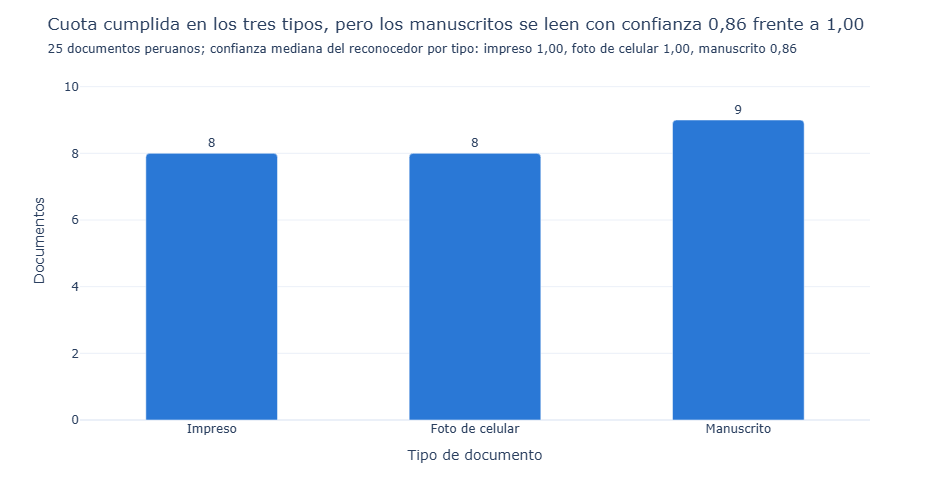

In [19]:
por_tipo = (docs.groupby("tipo", sort=False)
                .agg(documentos=("id", "size"), confianza=("confianza_mediana", "median"))
                .reindex(TIPOS).reset_index())
por_tipo["tipo_legible"] = por_tipo["tipo"].map(ETIQ_TIPO)
conf = dict(zip(por_tipo["tipo"], por_tipo["confianza"]))
peor = min(conf, key=conf.get)
titulo = (f"Cuota cumplida en los tres tipos, pero los {ETIQ_TIPO[peor].lower()}s se leen con confianza "
          f"{coma(conf[peor])} frente a {coma(max(conf.values()))}")

fig1 = px.bar(por_tipo, x="tipo_legible", y="documentos", text="documentos",
              labels={"tipo_legible": "Tipo de documento", "documentos": "Documentos"},
              hover_data={"confianza": ":.2f", "tipo_legible": False})
fig1.update_traces(marker_color=AZUL, textposition="outside", width=0.5)
fig1.update_layout(barcornerradius=4, yaxis_range=[0, por_tipo["documentos"].max() * 1.2], title=dict(
    text=titulo,
    subtitle=dict(text=("25 documentos peruanos; confianza mediana del reconocedor por tipo: " +
                        ", ".join(f"{ETIQ_TIPO[t].lower()} {coma(conf[t])}" for t in TIPOS)))))
fig1.show()

### 7.2 Duración por clip y minutos por fuente

Las duraciones van de unos segundos a 20 minutos, así que el eje es logarítmico. Por eso cada clip se dibuja como un punto y no como una barra: una barra en escala logarítmica no parte de cero y exagera las diferencias.

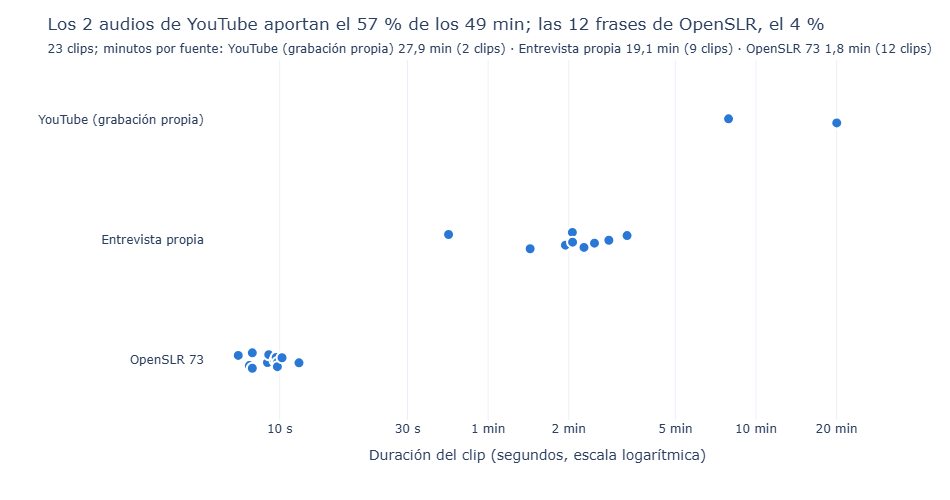

In [20]:
minutos_fuente = audios.groupby("fuente", sort=False)["duracion_seg"].sum().div(60).reindex(FUENTES_AUDIO)
pct = (100 * minutos_fuente / minutos_fuente.sum()).round(0)
yt = minutos_fuente.index[0]
titulo = (f"Los 2 audios de YouTube aportan el {pct[yt]:.0f} % de los {minutos_fuente.sum():.0f} min; "
          f"las 12 frases de OpenSLR, el {pct['OpenSLR 73']:.0f} %")

fig2 = px.strip(audios.assign(minutos=audios["duracion_seg"] / 60), x="duracion_seg", y="fuente",
                hover_name="id", hover_data={"minutos": ":.1f", "duracion_seg": ":.1f", "fuente": False},
                category_orders={"fuente": FUENTES_AUDIO},
                labels={"duracion_seg": "Duración del clip (segundos, escala logarítmica)", "fuente": ""})
fig2.update_traces(marker=dict(color=AZUL, size=11, line=dict(color="white", width=2)), jitter=0.35)
fig2.update_xaxes(type="log", tickvals=[5, 10, 30, 60, 120, 300, 600, 1200],
                  ticktext=["5 s", "10 s", "30 s", "1 min", "2 min", "5 min", "10 min", "20 min"])
fig2.update_layout(title=dict(text=titulo, subtitle=dict(text=(
    f"{len(audios)} clips; minutos por fuente: " +
    " · ".join(f"{f} {coma(m, 1)} min ({n} clips)" for f, m, n in
               zip(minutos_fuente.index, minutos_fuente, audios["fuente"].value_counts().reindex(FUENTES_AUDIO)))))))
fig2.show()

### 7.3 Longitud de los textos extraídos

Las longitudes van de 17 palabras, en una frase de OpenSLR, a casi 3700, en 20 minutos de podcast. Con intervalos del mismo ancho, casi todos los clips caerían en la primera barra. Por eso el histograma usa intervalos iguales en escala logarítmica: cada marca del eje vale más o menos el triple de la anterior.

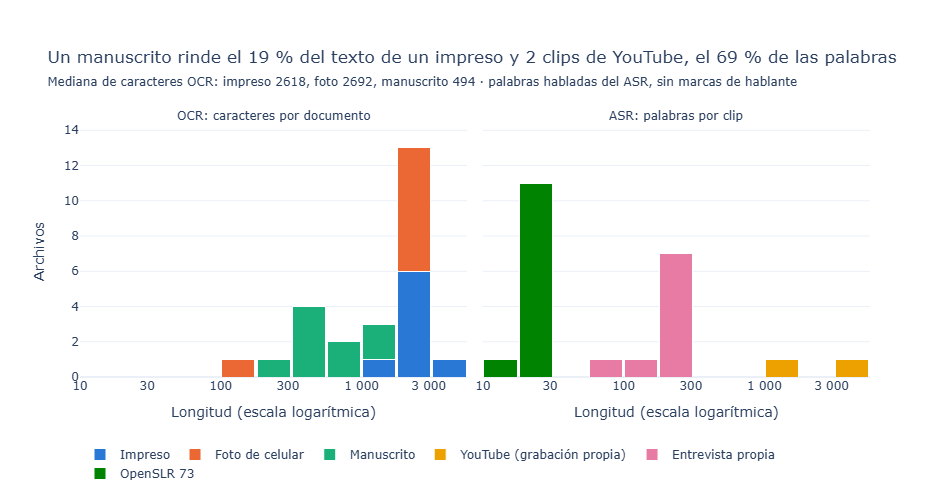

In [21]:
GRUPOS = {"Impreso": AZUL, "Foto de celular": NARANJA, "Manuscrito": AQUA,
          "YouTube (grabación propia)": AMARILLO, "Entrevista propia": MAGENTA, "OpenSLR 73": VERDE}
largos = pd.concat([
    pd.DataFrame({"medida": "OCR: caracteres por documento", "id": docs["id"],
                  "grupo": docs["tipo"].map(ETIQ_TIPO), "longitud": docs["caracteres"]}),
    pd.DataFrame({"medida": "ASR: palabras por clip", "id": audios["id"],
                  "grupo": audios["fuente"], "longitud": audios["palabras"]}),
])
largos["log_longitud"] = np.log10(largos["longitud"])
med = docs.groupby("tipo")["caracteres"].median()
mas_largos = audios.nlargest(2, "palabras")
top2 = mas_largos["palabras"].sum() / audios["palabras"].sum()
origen = "de YouTube" if (mas_largos["fuente"] == FUENTES_AUDIO[0]).all() else "largos"
titulo = (f"Un manuscrito rinde el {100 * med['manuscrito'] / med['impreso']:.0f} % del texto de un impreso "
          f"y 2 clips {origen}, el {100 * top2:.0f} % de las palabras")
MARCAS = [10, 30, 100, 300, 1000, 3000]

# Conteo por intervalo de un cuarto de década (10-18, 18-32, 32-56...), dibujado como barras apiladas
BORDES = np.arange(1, 4.01, 0.25)
largos["intervalo"] = pd.cut(largos["log_longitud"], BORDES, right=False, labels=BORDES[:-1] + 0.125).astype(float)
barras = largos.groupby(["medida", "grupo", "intervalo"]).size().reset_index(name="archivos")
barras["rango"] = [f"{10 ** (x - 0.125):,.0f} a {10 ** (x + 0.125):,.0f}".replace(",", " ") for x in barras["intervalo"]]

fig3 = px.bar(barras, x="intervalo", y="archivos", color="grupo", facet_col="medida",
              color_discrete_map=GRUPOS, category_orders={"grupo": list(GRUPOS), "medida": list(largos["medida"].unique())},
              custom_data=["rango"], labels={"intervalo": "Longitud (escala logarítmica)", "grupo": "", "archivos": "Archivos"})
fig3.update_traces(width=0.235, marker_line_color="white", marker_line_width=1,
                   hovertemplate="%{customdata[0]}: %{y} archivo(s)<extra>%{fullData.name}</extra>")
# Rango del eje y fijo: al exportar a PNG, el eje no calcula su rango con estos datos y queda en [-1, 4]
fig3.update_yaxes(range=[0, 1.1 * barras.groupby(["medida", "intervalo"])["archivos"].sum().max()])
fig3.update_xaxes(tickvals=np.log10(MARCAS), ticktext=[f"{m:,}".replace(",", " ") for m in MARCAS], range=[1, 3.75])
fig3.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig3.update_layout(barmode="stack", bargap=0.06, yaxis_title="Archivos", margin=dict(t=125),
                   legend=dict(orientation="h", y=-0.25),
                   title=dict(text=titulo, subtitle=dict(text=(
                       f"Mediana de caracteres OCR: impreso {med['impreso']:.0f}, foto {med['foto']:.0f}, "
                       f"manuscrito {med['manuscrito']:.0f} · palabras habladas del ASR, sin marcas de hablante"))))
fig3.show()

## 8. Validación: los 3 más largos y los 3 más cortos

Se buscan en la tabla los extremos de cada histograma y se mira su texto, para comprobar que las colas de los gráficos son lecturas reales y no errores del modelo. Los textos ya están seudonimizados.

In [22]:
def extremos(tabla, col, cols, n=3):
    orden = tabla.sort_values(col, ascending=False)
    return pd.concat([orden.head(n).assign(extremo="más largo"), orden.tail(n).assign(extremo="más corto")])[["extremo", *cols]]


pd.set_option("display.max_colwidth", 140)
val_docs = extremos(docs, "caracteres", ["id", "tipo", "lineas", "caracteres", "confianza_mediana"])
val_docs["inicio_del_texto"] = docs.set_index("id").loc[val_docs["id"], "texto_ocr"].str.replace("\n", " · ").str[:130].values
print(f"Caracteres OCR: mediana {docs['caracteres'].median():.0f}, rango {docs['caracteres'].min()}–{docs['caracteres'].max()}")
val_docs

Caracteres OCR: mediana 2240, rango 127–3428


,extremo,id,tipo,lineas,caracteres,confianza_mediana,inicio_del_texto
7,más largo,impreso8,impreso,57,3428,0.996,INSTITUTO NACIONAL DE DEFENSA DE LA COMPETENCIA Y DE LA PROTECCIÓN DE LA PROPIEDAD · INTELECTUAL-INDECOPI · ADJUDICACIÓN SIMPLIFIC
15,más largo,foto8,foto,45,3053,0.993,"en el numeral 8.1. En caso de requerirse más plazo, deberá solicitarlo de manera · oportuna y con la debida justificación a la Sub"
1,más largo,impreso2,impreso,46,3034,0.997,INSTITUTO NACIONAL DE DEFENSA DE LA COMPETENCIA Y DE LA PROTECCIÓN DE LA PROPIEDAD · INTELECTUAL- INDECOPI · ADJUDICACIÓN SIMPLIFI
21,más corto,manuscrito6,manuscrito,14,356,0.893,"$30 · Sr I. M. Rodriguer R. · Pambayeque · Prefecto del Dept?3 · Mi querido Fr Irefecto: · El Ir Pedro Adolfo Espinoga, · despues"
22,más corto,manuscrito7,manuscrito,7,202,0.649,apitulo 4. delor aburor acerca dellugar · SiendsLstemplaadeDi doneLon · n conuna mag.yalcançn Sobernme · econlantar ora gxandeabur
8,más corto,foto1,foto,8,127,0.998,t00 · REGION · TACNA · DISPOSICIONES Y PROCEDIMIENTOS · PARA LA ENTREGA RECEPCIÓN DEL · CARGO EN EL GOBIERNO REGIONAL DE · TACNA ·


In [23]:
val_audio = extremos(audios, "duracion_seg", ["id", "fuente", "duracion_seg", "palabras", "n_hablantes"])
val_audio["palabras_por_min"] = (60 * val_audio["palabras"] / val_audio["duracion_seg"]).round(0)
val_audio["inicio_del_texto"] = audios.set_index("id").loc[val_audio["id"], "texto_asr"].str[:130].values
print(f"Duración: mediana {audios['duracion_seg'].median():.0f} s, rango {audios['duracion_seg'].min()}–"
      f"{audios['duracion_seg'].max()} s · palabras: rango {audios['palabras'].min()}–{audios['palabras'].max()}")
val_audio

Duración: mediana 12 s, rango 7.0–1201.8 s · palabras: rango 17–3679


,extremo,id,fuente,duracion_seg,palabras,n_hablantes,palabras_por_min,inicio_del_texto
1,más largo,clip_002,YouTube (grabación propia),1201.8,3679,2,184.0,"[HABLANTE_1] Bueno, no conozco muchos otros lugares más de comida arequipeña, siendo la comida arequipeña probablemente una de las"
0,más largo,clip_001,YouTube (grabación propia),474.1,1331,3,168.0,"[HABLANTE_1] El otro tema que mencionaste, [PERSONA_01], fue el tema de lidiar como CEO, como líder de una empresa familiar. Que e"
5,más largo,clip_006,Entrevista propia,198.1,306,2,93.0,"[HABLANTE_1] Hola, soy yo, [PERSONA_08]. [HABLANTE_2] Hola, [PERSONA_08]. Oye, [PERSONA_08], ¿qué experiencia en tu jardín no te h"
17,más corto,clip_018,OpenSLR 73,7.9,19,1,144.0,Con la aguja y el hilo quirúrgico va a tratar de coserle la herida para que pare de sangrar
18,más corto,clip_019,OpenSLR 73,7.7,22,1,171.0,Estoy revisando los datos para el informe que voy a dar mañana y no entiendo bien lo que está pasando en Cataluña
11,más corto,clip_012,OpenSLR 73,7.0,21,1,180.0,"Ya vi las fotos que subiste ayer a la red, te ves muy bien, te queda muy bien el color rojo."


**Lectura de los extremos.**

- **Documentos largos.** Son páginas completas de las bases del Indecopi y de la directiva de Tacna, con más de 3000 caracteres y confianza de 0,99. Son lecturas reales de páginas densas.
- **Documentos cortos.** Cada uno es corto por una razón distinta:
  - `foto1` es la portada de la directiva: tiene pocas palabras, pero se lee bien (confianza 0,998).
  - `manuscrito7`, un manuscrito antiguo de la Biblioteca Nacional de España, es corto porque el modelo falla: lee 7 líneas con confianza 0,65 y el texto sale casi ilegible.
  - `manuscrito6`, la carta de Piérola, queda a medio camino: los nombres y el saludo se reconocen, pero con errores.

  La cola corta del histograma mezcla entonces documentos breves y fallas del OCR. La Parte 2 separa esos dos casos con el CER.
- **Audios.** Los extremos son coherentes con su fuente. Los dos podcasts se hablan a 168 y 184 palabras por minuto, que es un ritmo de conversación fluida. La entrevista más larga va a 93, por las pausas y las respuestas cortas del niño. Las frases de OpenSLR duran de 7 a 8 s y tienen entre 19 y 22 palabras, como sus guiones.